Cleaned column names: Index(['Index', 'Code', 'Name', 'Count'], dtype='object')
DataFrame after cleaning:
   Index  Code                                             Name  Count
0      1   AA0                                     Aspen forest  64389
1      2   AA1                                      Pine forest   5199
2      3   AA2                Beech forest with deciduous woods   2884
3      4   AB0                               Douglas fir forest  11593
4      5   AJ0  Mixed spruce forest with native deciduous woods  18120
5      6   AJ1                                 Oak-beech forest   2590
6      7   AK0                                       Oak forest    869
7      8   AS0                                     Beech forest   1063
Shape of classification_tree_array: (326, 840)
First few values of classification_tree_array:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
Variables in the .mat file:
LidarAGB
LidarCHM
easting_axis
northing_axis
Shape of LidarCHM: (32

/var/tmp/ipykernel_3059/3970412699.py:172: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45, ha='right')
/var/tmp/ipykernel_3059/3970412699.py:172: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45, ha='right')
/var/tmp/ipykernel_3059/3970412699.py:172: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45, ha='right')
/var/tmp/ipykernel_3059/3970412699.py:172: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45, ha='right')


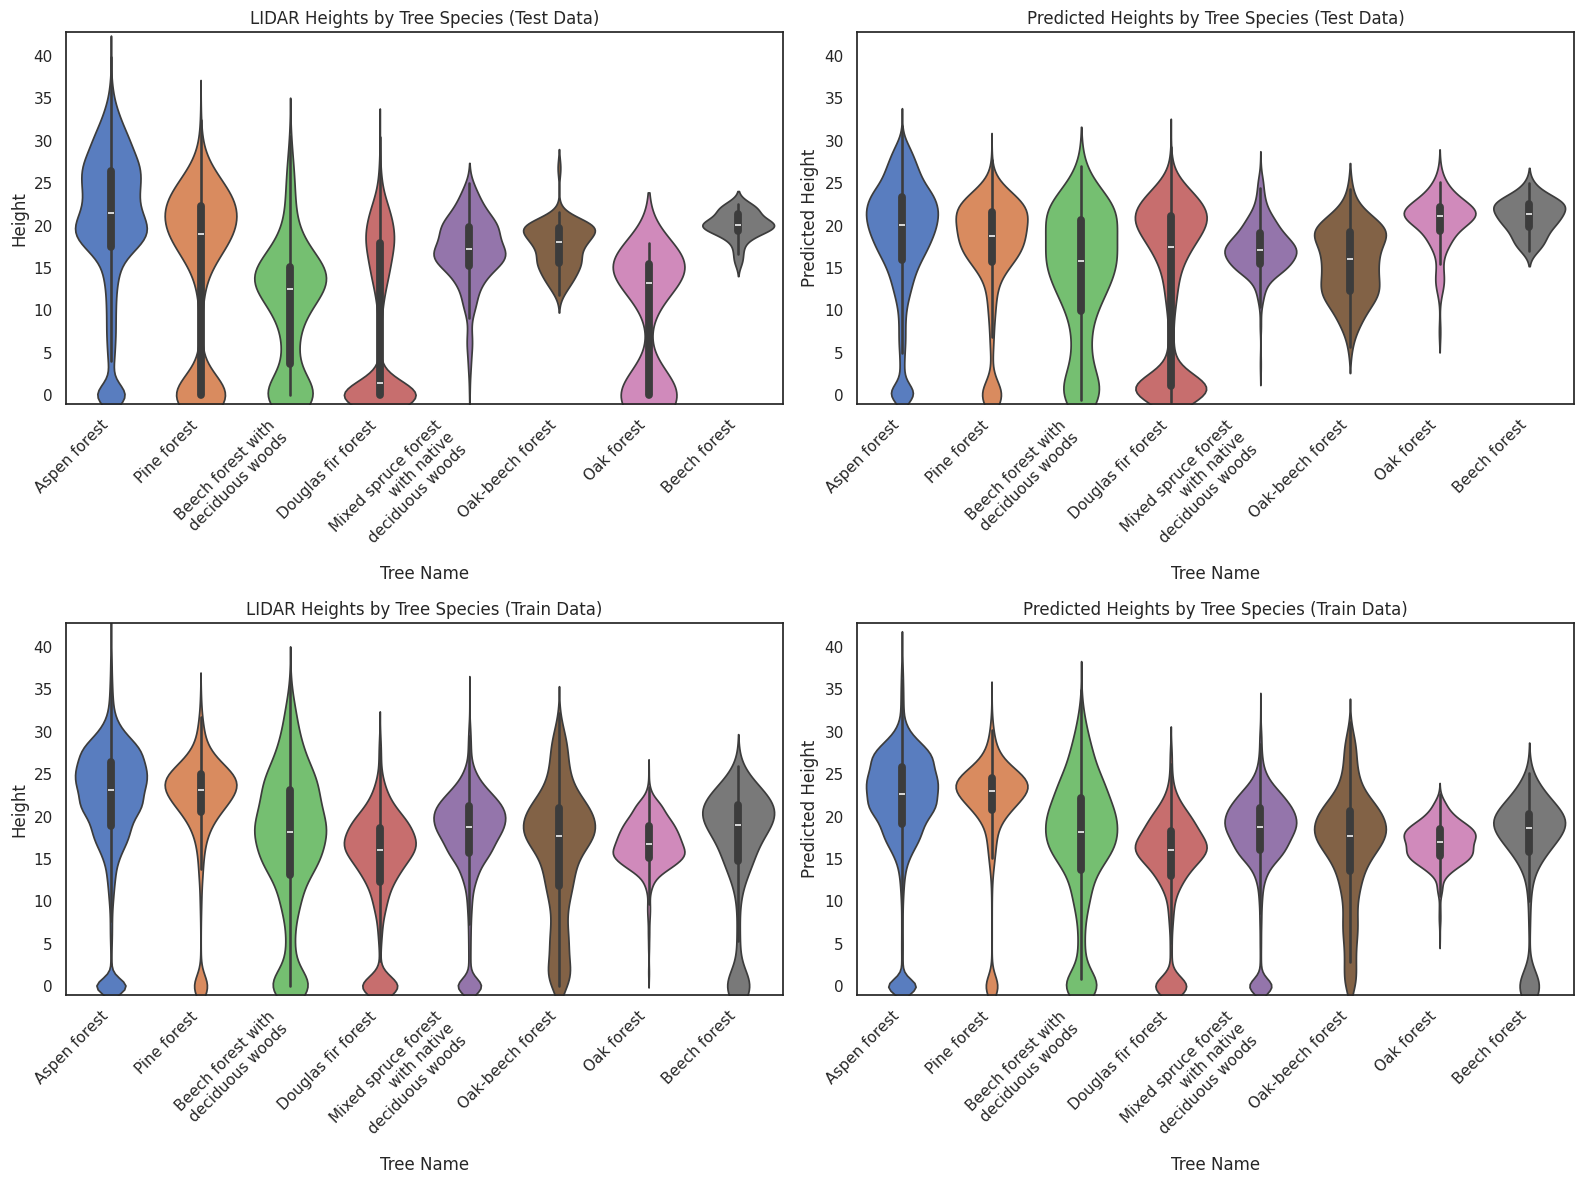

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
import tifffile as tiff
import seaborn as sns
import os
import textwrap

# File paths
classification_tree_file = "/home/laura93schade/data/tree_species/tree_species_index_info.txt"
tree_classification_tif = '/home/laura93schade/data/tree_species/vm_btpolygonproved_target_clip_mask_chm_rev_flipped.tif'
#predictions_test_file = '/home/laura93schade/local/lidar/dname_geo_split_square__polunion:_no__target_lidar__timelim_10000.0__modelset_best_quality__tsp_1.0__polarim_1__colset_withx__uuid_893f7a0f-/predictions_test.csv'
#predictions_train_file = '/home/laura93schade/local/lidar/dname_geo_split_square__polunion:_no__target_lidar__timelim_10000.0__modelset_best_quality__tsp_1.0__polarim_1__colset_withx__uuid_893f7a0f-/predictions_train.csv'
predictions_test_file = '/home/laura93schade/local/lidar/dname_geo_split_quadrants__polunion:_no__target_lidar__timelim_2000.0__modelset_best_quality__tsp_1.0__polarim_1__colset_withx__uuid_b3b4c16f-/predictions_test.csv'
predictions_train_file = '/home/laura93schade/local/lidar/dname_geo_split_quadrants__polunion:_no__target_lidar__timelim_2000.0__modelset_best_quality__tsp_1.0__polarim_1__colset_withx__uuid_b3b4c16f-/predictions_train.csv'
parent_path = '/data/2024-esl-biomasssar-development-landing/tomosar-matlab/'
band_opt = 'P'
lidar_path = f"{parent_path}{band_opt}/PowerCubeGeocod/LidarUTM.mat"

# Load classification data
df_tree_species = pd.read_csv(classification_tree_file)
df_tree_species.columns = df_tree_species.columns.str.strip()
df_tree_species['Name'] = df_tree_species['Name'].str.strip()  # Remove leading/trailing spaces
print("Cleaned column names:", df_tree_species.columns)

# Remove any unexpected classes
df_tree_species = df_tree_species[df_tree_species['Name'] != '1']
print("DataFrame after cleaning:")
print(df_tree_species.head(10))

# Load TIFF file
tree_classification_tif = tiff.imread(tree_classification_tif)
classification_tree_array = np.array(tree_classification_tif)

# Print the shape and first few values of the classification data
print(f"Shape of classification_tree_array: {classification_tree_array.shape}")
print("First few values of classification_tree_array:")
print(classification_tree_array[:5, :5])

# Load LiDAR data
lidar_data = loadmat(lidar_path)
LidarCHM = lidar_data['LidarCHM']

# List variables in the .mat file
print("Variables in the .mat file:")
for key in lidar_data.keys():
    if not key.startswith('__'):
        print(key)

# Check the shape and first few values of the LIDAR data
print(f"Shape of LidarCHM: {LidarCHM.shape}")
print("First few values of LidarCHM:")
print(LidarCHM[:5, :5])

# Ensure shapes match
if classification_tree_array.shape != LidarCHM.shape:
    raise ValueError("Shape mismatch between classification data and LiDAR data.")

# Initialize dictionary to hold lidar heights for each class
class_lidar_heights = {index: {'test': [], 'train': []} for index in df_tree_species['Index'].values}
print(f"class_lidar_heights {class_lidar_heights}")

# Load predictions test data
if os.path.isfile(predictions_test_file):
    predictions_test_df = pd.read_csv(predictions_test_file)
    print("Sample Test Predictions Data:")
    print(predictions_test_df.head())
else:
    raise FileNotFoundError(f"No predictions file found at {predictions_test_file}")

# Load predictions train data
if os.path.isfile(predictions_train_file):
    predictions_train_df = pd.read_csv(predictions_train_file)
    print("Sample Train Predictions Data:")
    print(predictions_train_df.head())
else:
    raise FileNotFoundError(f"No predictions file found at {predictions_train_file}")

set_testing = set((predictions_test_df['original_x'].astype(str) + '-' + predictions_test_df['original_y'].astype(str)).values)
set_train = set((predictions_train_df['original_x'].astype(str) + '-' + predictions_train_df['original_y'].astype(str)).values)

# Fill dictionary with lidar heights for each class
for i in range(classification_tree_array.shape[0]):
    for j in range(classification_tree_array.shape[1]):
        class_index = classification_tree_array[i, j]
        is_the_coordinate_on_the_testing = (str(i)+'-'+str(j)) in set_testing
        is_the_coordinate_on_the_train = (str(i)+'-'+str(j)) in set_train
        if class_index in class_lidar_heights and not np.isnan(LidarCHM[i, j]):
            if is_the_coordinate_on_the_testing:
                class_lidar_heights[class_index]['test'].append(LidarCHM[i, j])
            if is_the_coordinate_on_the_train:
                class_lidar_heights[class_index]['train'].append(LidarCHM[i, j])

# Convert to DataFrames for plotting
data_lidar_heights_test = []
data_lidar_heights_train = []
index_to_name = dict(zip(df_tree_species['Index'], df_tree_species['Name']))
for class_index, heights in class_lidar_heights.items():
    if len(heights['test']) > 0:
        data_lidar_heights_test.extend([(index_to_name[class_index], height) for height in heights['test']])
    if len(heights['train']) > 0:
        data_lidar_heights_train.extend([(index_to_name[class_index], height) for height in heights['train']])

df_lidar_heights_test = pd.DataFrame(data_lidar_heights_test, columns=['Tree Name', 'Height'])
df_lidar_heights_train = pd.DataFrame(data_lidar_heights_train, columns=['Tree Name', 'Height'])
df_lidar_heights_test['Tree Name'] = df_lidar_heights_test['Tree Name'].str.strip()
df_lidar_heights_train['Tree Name'] = df_lidar_heights_train['Tree Name'].str.strip()

# Ensure the columns we are using are present
expected_columns = ['predicted', 'original_x', 'original_y']
for col in expected_columns:
    if col not in predictions_test_df.columns:
        raise ValueError(f"Expected column '{col}' not found in predictions test data.")
for col in expected_columns:
    if col not in predictions_train_df.columns:
        raise ValueError(f"Expected column '{col}' not found in predictions train data.")

# Initialize dictionary to hold predicted heights for each class
class_predicted_heights_test = {index: [] for index in df_tree_species['Index'].values}
class_predicted_heights_train = {index: [] for index in df_tree_species['Index'].values}

# Map the test predictions to classes
for _, row in predictions_test_df.iterrows():
    predicted_height = row['predicted']
    orig_x = int(row['original_x'])
    orig_y = int(row['original_y'])
    if 0 <= orig_x < classification_tree_array.shape[0] and 0 <= orig_y < classification_tree_array.shape[1]:
        class_index = classification_tree_array[orig_x, orig_y]
        if not np.isnan(predicted_height) and class_index in class_predicted_heights_test:
            class_predicted_heights_test[class_index].append(predicted_height)

# Convert to DataFrame for plotting
data_pred_test = []
for class_index, heights in class_predicted_heights_test.items():
    if len(heights) > 0:
        data_pred_test.extend([(index_to_name[class_index], height) for height in heights])

df_predicted_heights_test = pd.DataFrame(data_pred_test, columns=['Tree Name', 'Predicted Height'])
df_predicted_heights_test['Tree Name'] = df_predicted_heights_test['Tree Name'].str.strip()

# Map the train predictions to classes
for _, row in predictions_train_df.iterrows():
    predicted_height = row['predicted']
    orig_x = int(row['original_x'])
    orig_y = int(row['original_y'])
    if 0 <= orig_x < classification_tree_array.shape[0] and 0 <= orig_y < classification_tree_array.shape[1]:
        class_index = classification_tree_array[orig_x, orig_y]
        if not np.isnan(predicted_height) and class_index in class_predicted_heights_train:
            class_predicted_heights_train[class_index].append(predicted_height)

# Convert to DataFrame for plotting
data_pred_train = []
for class_index, heights in class_predicted_heights_train.items():
    if len(heights) > 0:
        data_pred_train.extend([(index_to_name[class_index], height) for height in heights])

df_predicted_heights_train = pd.DataFrame(data_pred_train, columns=['Tree Name', 'Predicted Height'])
df_predicted_heights_train['Tree Name'] = df_predicted_heights_train['Tree Name'].str.strip()

# Plotting

# Determine the overall min and max heights from the data
min_height = min(df_lidar_heights_train['Height'].min(), df_lidar_heights_test['Height'].min(), df_predicted_heights_test['Predicted Height'].min(), df_predicted_heights_train['Predicted Height'].min())
max_height = max(df_lidar_heights_train['Height'].max(), df_lidar_heights_test['Height'].max(), df_predicted_heights_test['Predicted Height'].max(), df_predicted_heights_train['Predicted Height'].max())

plt.figure(figsize=(16, 12))

# Function to wrap x labels
def wrap_labels(ax, width):
    labels = [textwrap.fill(label.get_text(), width) for label in ax.get_xticklabels()]
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_ylim(min_height, max_height)

# Plot for Test Data
plt.subplot(2, 2, 1)
sns.violinplot(x='Tree Name', y='Height', data=df_lidar_heights_test, hue='Tree Name', legend=False)
plt.title('LIDAR Heights by Tree Species (Test Data)')
wrap_labels(plt.gca(), 20)

plt.subplot(2, 2, 2)
sns.violinplot(x='Tree Name', y='Predicted Height', data=df_predicted_heights_test, hue='Tree Name', legend=False)
plt.title('Predicted Heights by Tree Species (Test Data)')
wrap_labels(plt.gca(), 20)

# Plot for Train Data
plt.subplot(2, 2, 3)
sns.violinplot(x='Tree Name', y='Height', data=df_lidar_heights_train, hue='Tree Name', legend=False)
plt.title('LIDAR Heights by Tree Species (Train Data)')
wrap_labels(plt.gca(), 20)

plt.subplot(2, 2, 4)
sns.violinplot(x='Tree Name', y='Predicted Height', data=df_predicted_heights_train, hue='Tree Name', legend=False)
plt.title('Predicted Heights by Tree Species (Train Data)')
wrap_labels(plt.gca(), 20)

plt.tight_layout()
plt.show()


/var/tmp/ipykernel_3059/3201243544.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=0, ha='center', color='white')
/var/tmp/ipykernel_3059/3201243544.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=0, ha='center', color='white')
/var/tmp/ipykernel_3059/3201243544.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=0, ha='center', color='white')
/var/tmp/ipykernel_3059/3201243544.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=0, ha='center', color='white')


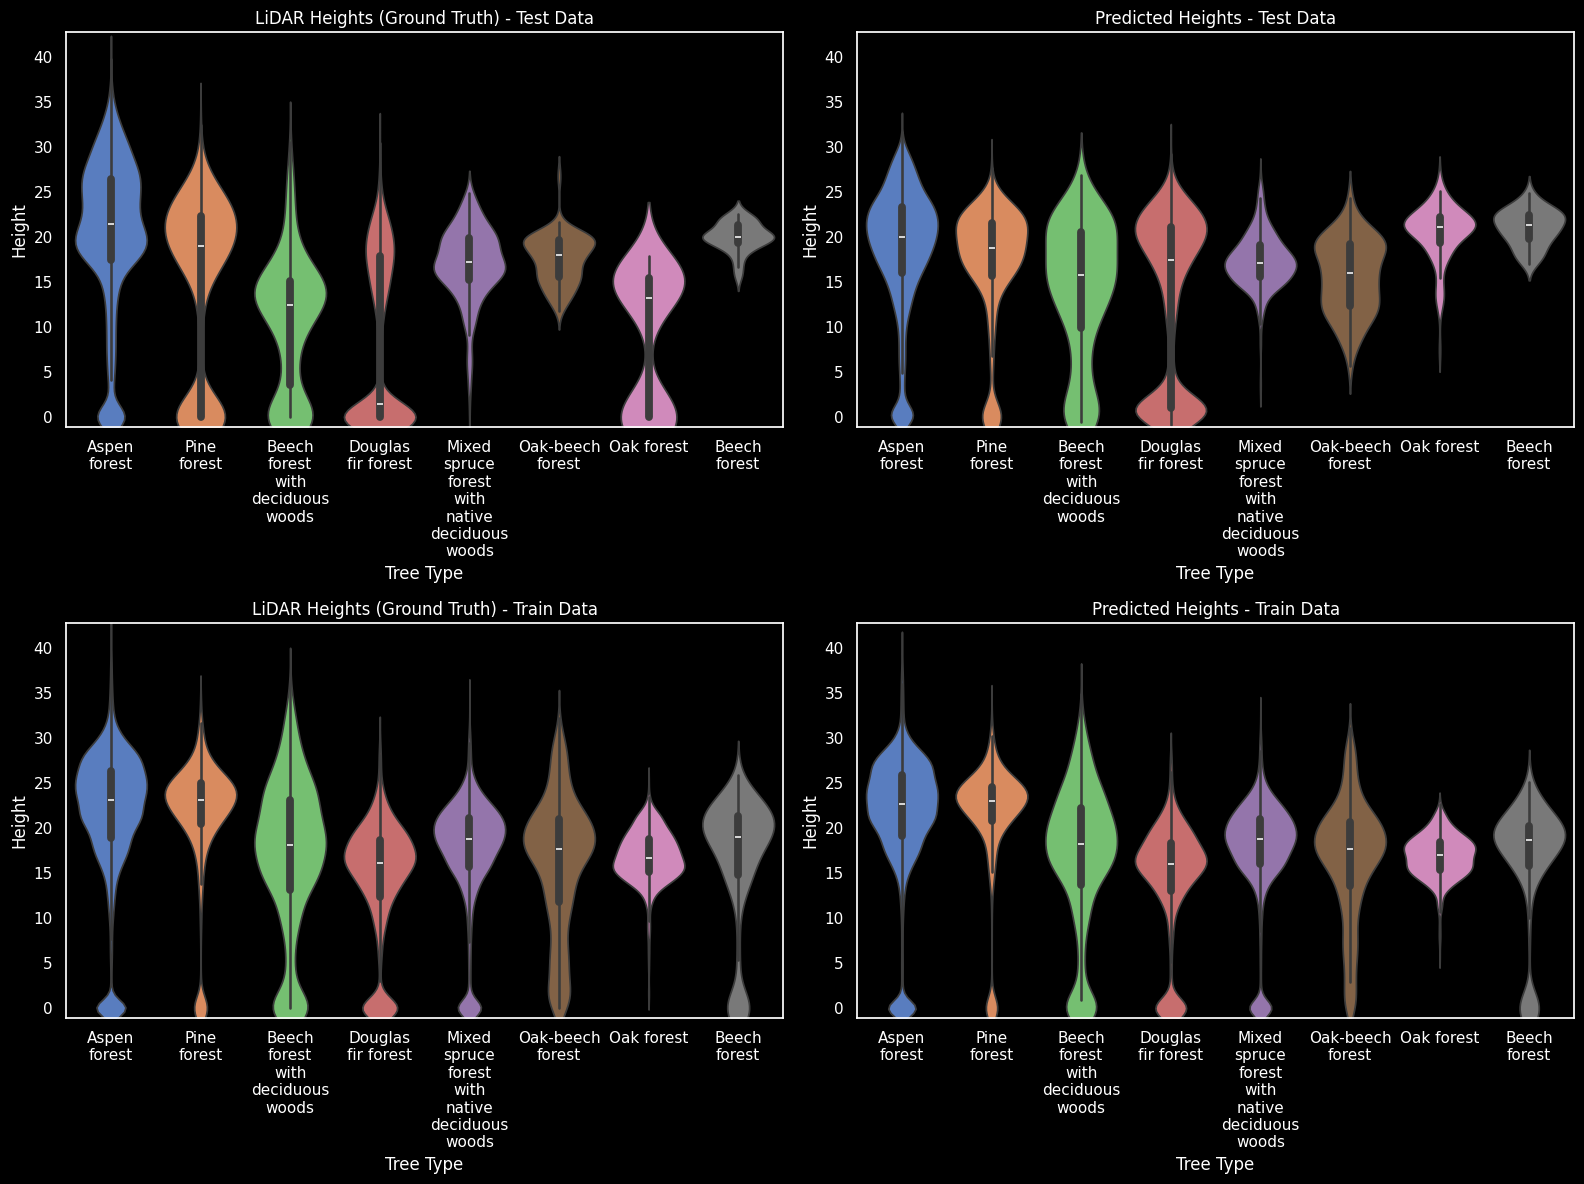

In [13]:
# Set the style for the plot
plt.style.use('dark_background')
sns.set(style='white', palette='muted')

# Determine the overall min and max heights from the data
min_height = min(df_lidar_heights_train['Height'].min(), df_lidar_heights_test['Height'].min(), df_predicted_heights_test['Predicted Height'].min(), df_predicted_heights_train['Predicted Height'].min())
max_height = max(df_lidar_heights_train['Height'].max(), df_lidar_heights_test['Height'].max(), df_predicted_heights_test['Predicted Height'].max(), df_predicted_heights_train['Predicted Height'].max())

# Create a figure with a black background
fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor='black')

# Function to wrap x labels
def wrap_labels(ax, width):
    labels = [textwrap.fill(label.get_text(), width) for label in ax.get_xticklabels()]
    ax.set_xticklabels(labels, rotation=0, ha='center', color='white')

# Common settings for each plot
def set_common_settings(ax, title):
    ax.set_title(title, color='white')
    ax.set_xlabel('Tree Type', color='white')
    ax.set_ylabel('Height', color='white')
    wrap_labels(ax, 10)
    ax.patch.set_facecolor('black')
    ax.spines['top'].set_color('white')
    ax.spines['bottom'].set_color('white')
    ax.spines['left'].set_color('white')
    ax.spines['right'].set_color('white')
    ax.tick_params(axis='x', colors='white')
    ax.tick_params(axis='y', colors='white')
    ax.set_ylim(min_height, max_height)

# Plot for Test Data - LiDAR Heights
sns.violinplot(ax=axes[0, 0], x='Tree Name', y='Height', data=df_lidar_heights_test, hue='Tree Name', legend=False)
set_common_settings(axes[0, 0], 'LiDAR Heights (Ground Truth) - Test Data')

# Plot for Test Data - Predicted Heights
sns.violinplot(ax=axes[0, 1], x='Tree Name', y='Predicted Height', data=df_predicted_heights_test, hue='Tree Name', legend=False)
set_common_settings(axes[0, 1], 'Predicted Heights - Test Data')

# Plot for Train Data - LiDAR Heights
sns.violinplot(ax=axes[1, 0], x='Tree Name', y='Height', data=df_lidar_heights_train, hue='Tree Name', legend=False)
set_common_settings(axes[1, 0], 'LiDAR Heights (Ground Truth) - Train Data')

# Plot for Train Data - Predicted Heights
sns.violinplot(ax=axes[1, 1], x='Tree Name', y='Predicted Height', data=df_predicted_heights_train, hue='Tree Name', legend=False)
set_common_settings(axes[1, 1], 'Predicted Heights - Train Data')

# Adjust layout and show plot
plt.tight_layout()
plt.show()


In [14]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# Clean column names
df_predicted_heights_test.columns = df_predicted_heights_test.columns.str.strip()
df_lidar_heights_test.columns = df_lidar_heights_test.columns.str.strip()
df_predicted_heights_train.columns = df_predicted_heights_train.columns.str.strip()
df_lidar_heights_train.columns = df_lidar_heights_train.columns.str.strip()

# Initialize dictionary to hold MAE for each class
class_mae = {}

# Ensure no unexpected NaNs
df_predicted_heights_test.dropna(subset=['Tree Name', 'Predicted Height'], inplace=True)
df_lidar_heights_test.dropna(subset=['Tree Name', 'Height'], inplace=True)
df_predicted_heights_train.dropna(subset=['Tree Name', 'Predicted Height'], inplace=True)
df_lidar_heights_train.dropna(subset=['Tree Name', 'Height'], inplace=True)

# Ensure that 'Tree Name' columns are treated as the index for alignment
df_predicted_heights_test.set_index('Tree Name', inplace=True)
df_lidar_heights_test.set_index('Tree Name', inplace=True)
df_predicted_heights_train.set_index('Tree Name', inplace=True)
df_lidar_heights_train.set_index('Tree Name', inplace=True)

# For each tree class, calculate the MAE
for class_index in df_tree_species['Index'].values:
    # Get tree name for class index
    tree_name = index_to_name[class_index]

    # Extract predicted and actual heights for the test set
    if tree_name in df_predicted_heights_test.index and tree_name in df_lidar_heights_test.index:
        predicted_test_heights = df_predicted_heights_test.loc[tree_name, 'Predicted Height']
        actual_test_heights = df_lidar_heights_test.loc[tree_name, 'Height']
    else:
        predicted_test_heights = []
        actual_test_heights = []

    # Extract predicted and actual heights for the train set
    if tree_name in df_predicted_heights_train.index and tree_name in df_lidar_heights_train.index:
        predicted_train_heights = df_predicted_heights_train.loc[tree_name, 'Predicted Height']
        actual_train_heights = df_lidar_heights_train.loc[tree_name, 'Height']
    else:
        predicted_train_heights = []
        actual_train_heights = []

    # Combine test and train data
    all_predicted_heights = np.concatenate((np.array(predicted_test_heights).ravel(), np.array(predicted_train_heights).ravel()))
    all_actual_heights = np.concatenate((np.array(actual_test_heights).ravel(), np.array(actual_train_heights).ravel()))

    if len(all_predicted_heights) > 0 and len(all_actual_heights) > 0:
        try:
            mae = mean_absolute_error(all_actual_heights, all_predicted_heights)
            class_mae[tree_name] = mae
        except Exception as e:
            print(f"Error calculating MAE for {tree_name}: {e}")

# Convert the results to a DataFrame for easy viewing
df_class_mae = pd.DataFrame(list(class_mae.items()), columns=['Tree Name', 'MAE'])
df_class_mae = df_class_mae.sort_values(by='MAE')

# Print MAE results
print("Mean Absolute Error (MAE) for each class:")
print(df_class_mae)


Mean Absolute Error (MAE) for each class:
                                         Tree Name       MAE
7                                     Beech forest  1.379596
6                                       Oak forest  2.526933
4  Mixed spruce forest with native deciduous woods  2.952335
0                                     Aspen forest  3.684354
1                                      Pine forest  4.529518
3                               Douglas fir forest  4.966697
5                                 Oak-beech forest  5.030426
2                Beech forest with deciduous woods  5.238243


In [15]:
# Combine all predicted and actual heights for the overall MAE calculation

# Extract all predicted and actual heights for the test set
all_predicted_test_heights = df_predicted_heights_test['Predicted Height'].values
all_actual_test_heights = df_lidar_heights_test['Height'].values

# Extract all predicted and actual heights for the train set
all_predicted_train_heights = df_predicted_heights_train['Predicted Height'].values
all_actual_train_heights = df_lidar_heights_train['Height'].values

# Combine test and train data
all_predicted_heights = np.concatenate((all_predicted_test_heights, all_predicted_train_heights))
all_actual_heights = np.concatenate((all_actual_test_heights, all_actual_train_heights))

# Calculate the overall MAE
overall_mae = mean_absolute_error(all_actual_heights, all_predicted_heights)

# Print the overall MAE
print(f"Overall Mean Absolute Error (MAE): {overall_mae}")


Overall Mean Absolute Error (MAE): 3.789269407077858


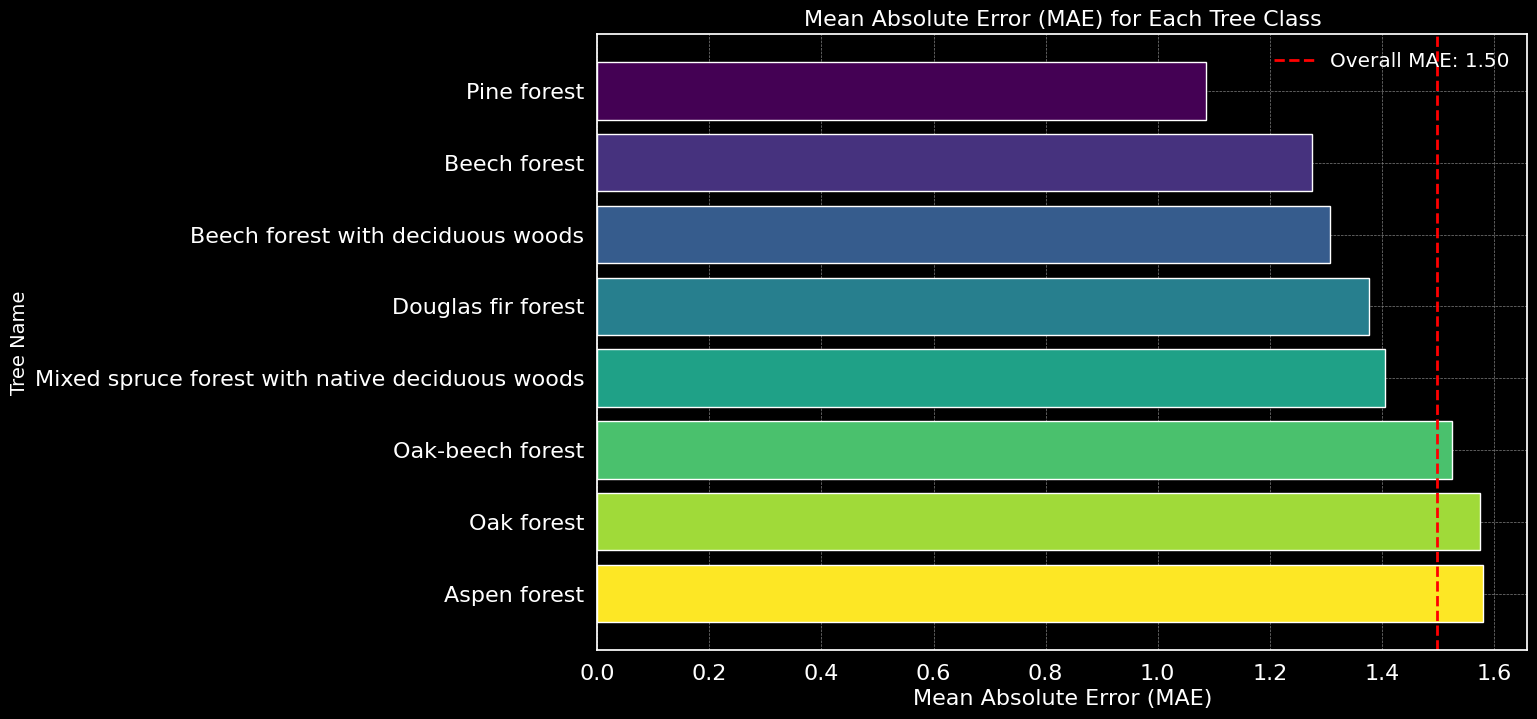

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# Set the style of the plot
plt.style.use('dark_background')

# Generate a list of different colors
colors = plt.cm.viridis(np.linspace(0, 1, len(df_class_mae)))

# Overall MAE value
overall_mae = 1.497683328780947

# Plot the MAE as a horizontal bar plot
plt.figure(figsize=(12, 8))
bars = plt.barh(df_class_mae['Tree Name'], df_class_mae['MAE'], color=colors)

# Add a vertical line for the overall MAE in red
plt.axvline(overall_mae, color='red', linestyle='--', linewidth=2, label=f'Overall MAE: {overall_mae:.2f}')

# Add labels and title with white color and increased size
plt.xlabel('Mean Absolute Error (MAE)', color='white', fontsize=16)
plt.ylabel('Tree Name', color='white', fontsize=14)
plt.title('Mean Absolute Error (MAE) for Each Tree Class', color='white', fontsize=16)

# Customizing the ticks and grid
plt.tick_params(axis='both', colors='white', labelsize=16)
plt.grid(color='grey', linestyle='--', linewidth=0.5)

# Add legend and customize its appearance
legend = plt.legend(frameon=False, fontsize='large', loc='upper right')
for text in legend.get_texts():
    text.set_color('white')

# Invert y-axis to have the highest MAE on top
plt.gca().invert_yaxis()

# Show the plot
plt.show()



In [39]:
import pandas as pd
import numpy as np
from scipy.stats import kurtosis
from sklearn.metrics import mean_squared_error

def calculate_statistics(df_ground_truth, df_predicted):
    stats_dict = {
        'Min': round(df_ground_truth['Height'].min(), 2),
        'Max': round(df_ground_truth['Height'].max(), 2),
        'Mean': round(df_ground_truth['Height'].mean(), 2),
        'Std Dev': round(df_ground_truth['Height'].std(), 2),
        'Kurtosis': round(kurtosis(df_ground_truth['Height']), 2),
        'RMSE': round(np.sqrt(mean_squared_error(df_ground_truth['Height'], df_predicted['Predicted Height'])), 2)
    }
    return stats_dict

# Initialize dictionaries to hold statistics
stats_test = {}
stats_train = {}

# Compute statistics for each tree name
for tree_name in df_lidar_heights_test.index.unique():
    if tree_name in df_predicted_heights_test.index:
        gt_test = df_lidar_heights_test.loc[tree_name]
        pred_test = df_predicted_heights_test.loc[tree_name]
        stats_test[tree_name] = calculate_statistics(gt_test, pred_test)
        
    if tree_name in df_predicted_heights_train.index:
        gt_train = df_lidar_heights_train.loc[tree_name]
        pred_train = df_predicted_heights_train.loc[tree_name]
        stats_train[tree_name] = calculate_statistics(gt_train, pred_train)

# Convert dictionaries to DataFrames for easier viewing
df_stats_test = pd.DataFrame(stats_test).T
df_stats_train = pd.DataFrame(stats_train).T

# Print results
print("Statistics for Test Data:")
print(df_stats_test)

print("\nStatistics for Train Data:")
print(df_stats_train)


Statistics for Test Data:
                                                  Min    Max   Mean  Std Dev  \
Aspen forest                                     0.36  42.52  23.35     5.68   
Pine forest                                      8.77  27.67  22.61     2.59   
Beech forest with deciduous woods                4.87  25.29  16.60     3.80   
Douglas fir forest                               1.89  26.42  16.31     3.46   
Mixed spruce forest with native deciduous woods  0.03  28.67  18.26     4.63   
Oak-beech forest                                 0.15  31.53  17.05     8.20   
Oak forest                                       1.40  22.92  16.24     2.61   
Beech forest                                     5.65  23.75  19.05     3.14   

                                                 Kurtosis  RMSE  
Aspen forest                                         0.81  5.28  
Pine forest                                          1.87  3.75  
Beech forest with deciduous woods                    0.

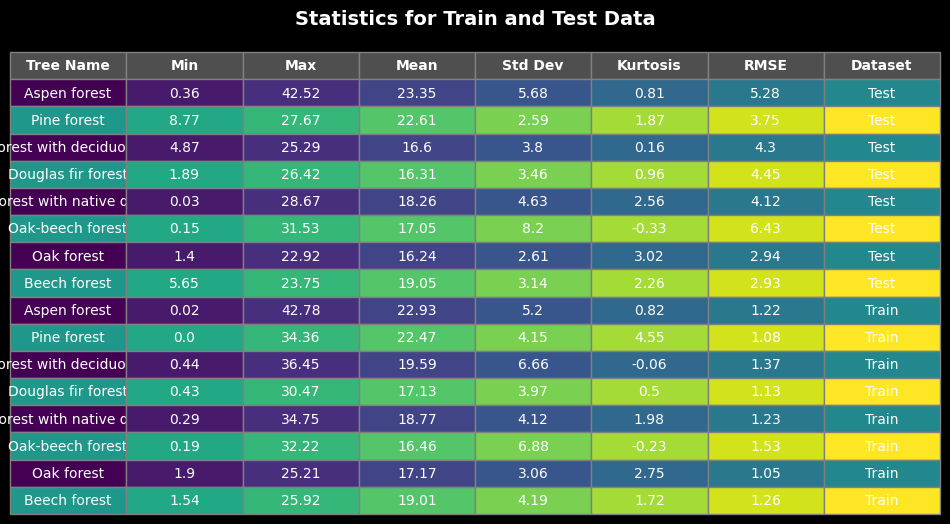

In [40]:
# Merge train and test statistics into one DataFrame for easier comparison
df_stats_test['Dataset'] = 'Test'
df_stats_train['Dataset'] = 'Train'

# Combine both DataFrames
df_stats_combined = pd.concat([df_stats_test, df_stats_train])

# Reset index to make 'Tree Name' a column for better display
df_stats_combined.reset_index(inplace=True)
df_stats_combined.rename(columns={'index': 'Tree Name'}, inplace=True)

# Create a plot with table
fig, ax = plt.subplots(figsize=(12, 6))  # Adjust size as needed
ax.axis('off')  # Hide axes

# Create table
table = ax.table(cellText=df_stats_combined.values,
                 colLabels=df_stats_combined.columns,
                 cellLoc='center',
                 loc='center',
                 bbox=[0, 0, 1, 1])  # Adjust bbox as needed

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.2)  # Adjust scaling as needed

# Set background color and other styles
colors = plt.cm.viridis(np.linspace(0, 1, len(df_stats_combined)))  # Get a colormap
for i, key in enumerate(table.get_celld().keys()):
    cell = table.get_celld()[key]
    if key[0] == 0:  # Header row
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#4F4F4F')  # Dark grey background
    else:
        cell.set_facecolor(colors[i % len(colors)])  # Different colors for each row
    cell.set_edgecolor('grey')

# Add title
plt.title('Statistics for Train and Test Data', fontsize=14, weight='bold', color='white', pad=20)

# Save the plot as an image
plt.savefig('statistics_table.png', bbox_inches='tight', dpi=300, facecolor='black')

# Show plot (optional)
plt.show()
